# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [4]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [5]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [6]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

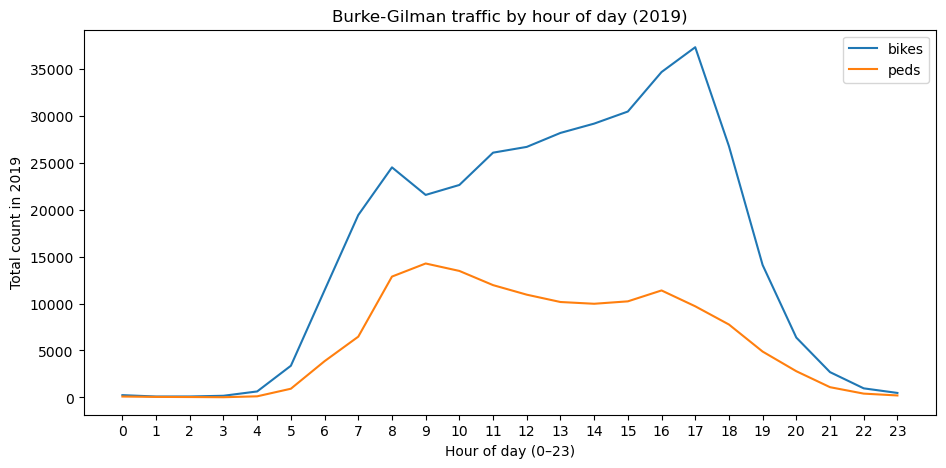

In [7]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

In [10]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)

df["total"] = df["bikes"] + df["peds"]

traffic = df.groupby("hour")["total"].sum()

print("Busiest hour:", traffic.idxmax())
print("Quietest hour:", traffic.idxmin())


Busiest hour: 17
Quietest hour: 2


**Your Q1 answer:**

*I define "busy" as the total number of bikes and pedestrians using the trail together. In real life, when we think about rush hour, we usually count different types of transportation, like cars, buses, and subways, because they are all part of how people travel. So for this dataset, I count both bikes and pedestrians for the calculations. I also think a busy hour should be a regular peak during the day, not just a special event like a marathon that brings a lot of pedestrians. From the graph, the busiest time is around 5 PM, while the quietest time is during the early morning. This might be because people are going to work or coming home.*

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

In [14]:
# Your code for Q2

print("Bikes:", by_hour["bikes"].idxmax())
print("Pedestrians:", by_hour["peds"].idxmax())



Bikes: 17
Pedestrians: 9


**Your Q2 answer:**

*The graph is the same as Part 1, so I just pulled out the busiest hour for bikes and peds. Cyclists are busiest around 5 PM, while pedestrians are busiest around 9 AM. This might mean to me that people prefer walking in the morning and biking in the late afternoon. However, I don't think this graph tells us too much about why people use the trail at different times. Probably would need more information to understand their reasons.*

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

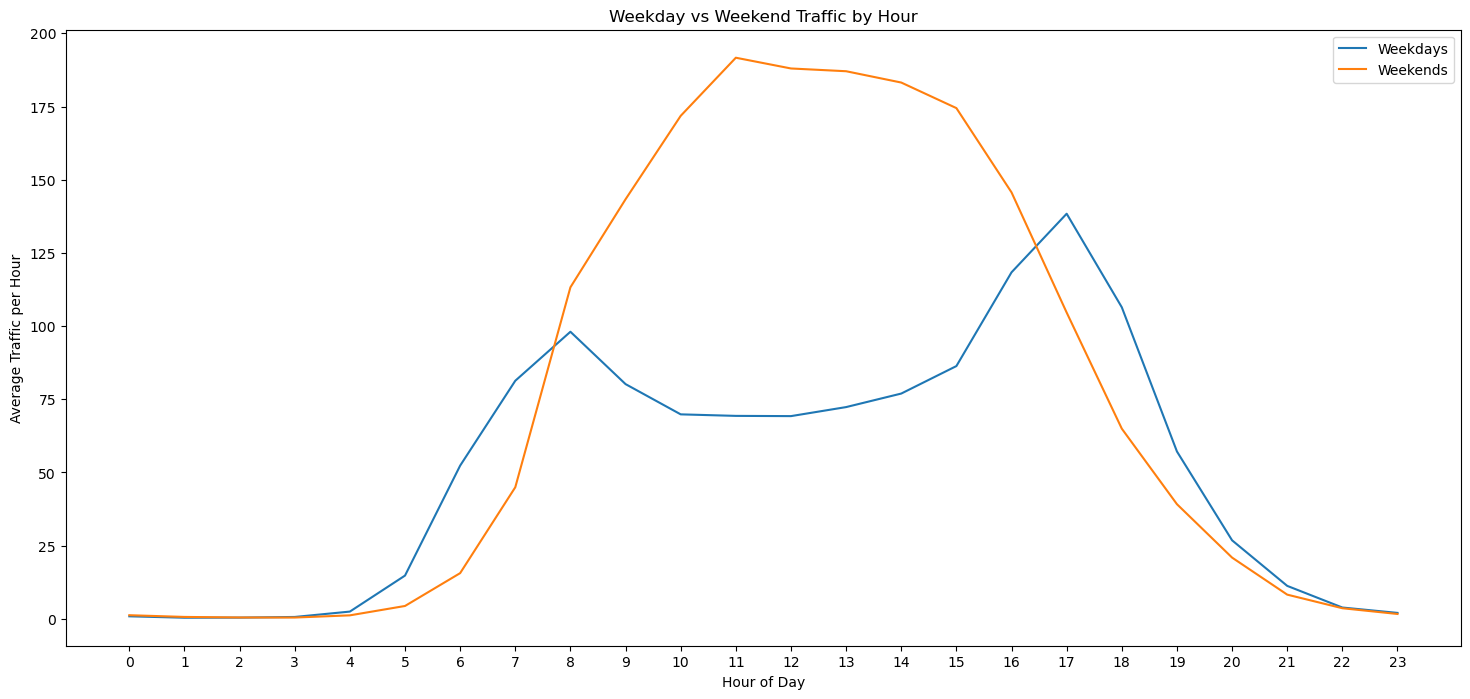

In [29]:
# Your code for Q3


# Separate weekdays and weekends
df["day_type"] = df["weekday"].isin(["Saturday", "Sunday"])

# Add bikes and pedestrians together
df["total"] = df["bikes"] + df["peds"]

# Find average traffic by hour
traffic = df.groupby(["hour", "day_type"])["total"].mean()

# Make a line graph
traffic.unstack().plot(figsize=(18, 8))
plt.title("Weekday vs Weekend Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic per Hour")
plt.xticks(range(0, 24))
plt.legend(["Weekdays", "Weekends"])
plt.show()




**Your Q3 answer:**

*I think a commuting pattern would show that more people using the trail during weekday mornings and evenings, especially around 8 AM and 5 PM. On weekends, from the graph it shows that people are using the trail more in the mid of the day so this means they are using it for fun.*

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

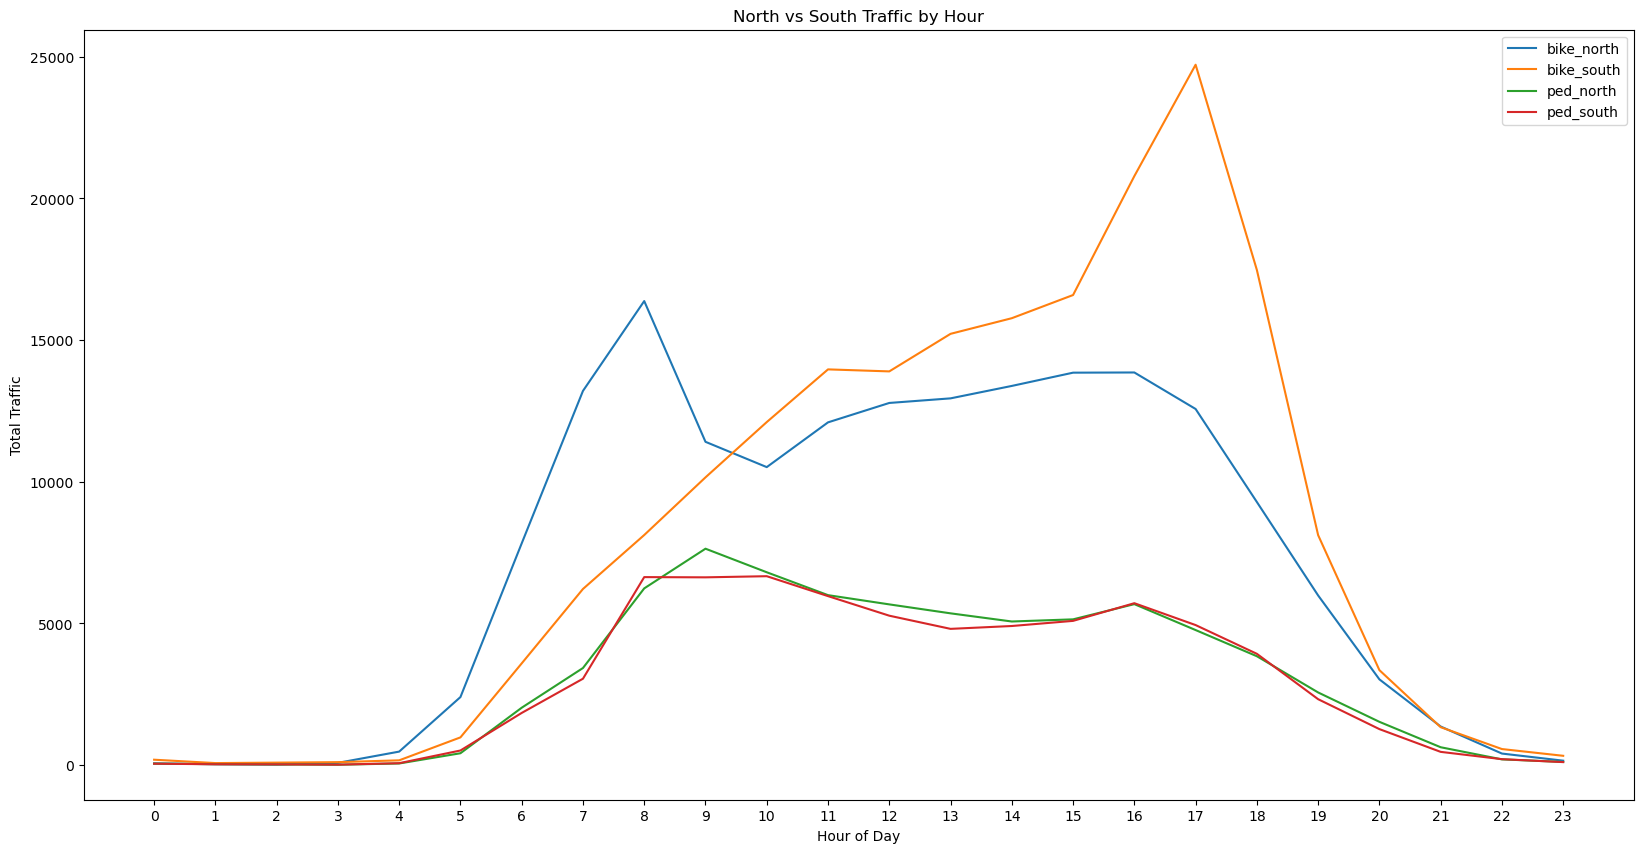

In [26]:
# Your code for Q4

direction = df.groupby("hour")[["bike_north", "bike_south", "ped_north", "ped_south"]].sum()

direction.plot(figsize=(20, 10))
plt.title("North vs South Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Traffic")
plt.xticks(range(0, 24))
plt.show()



**Your Q4 answer:**

*From the graph, I can see that cyclists travel more north in the morning, especially around 8 AM, while more cyclists travel south in the evening, around 5 PM; and there is a gap around 5000 between those data. This might mean people are using the trail to commute, going to work or school in the morning and returning home in the evening, and people might go out for fun in this time also which create the gap there. For pedestrians, there is a more similar pattern in both directions, so I don't see an exactly commuting pattern for peds.*

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*One limitation of this dataset is that it only counts how many bikes and pedestrians are using the trail, but it does not tell us why they are there. For example, in Q4, I found that more cyclists travel north in the morning and south in the evening, which might suggest commuting; and the gap between north and south data, I'm also just guessing there are people bike to south for fun. However, we cannot be sure the real reason of this pattern/data showing out, whether they are going to work, school, or just exercising. When doing the research and data collection it would be better to interpret the real reason of this data happening.*

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

Busiest day for bikes: Saturday
Busiest day for pedestrians: Sunday


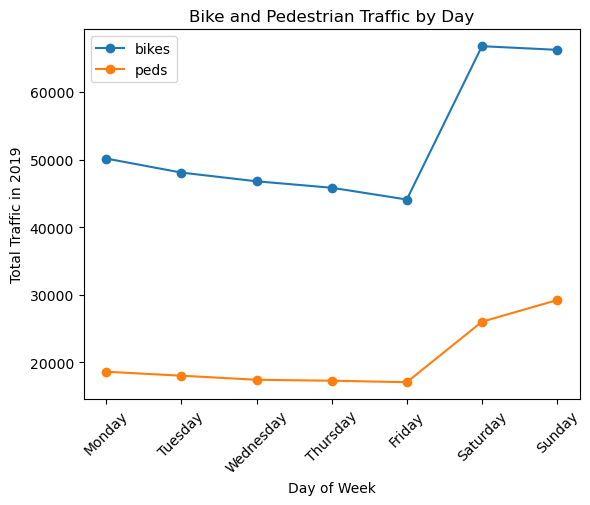

In [30]:

# Group traffic by day of the week
by_day = df.groupby("weekday")[["bikes", "peds"]].sum()

# Put days in order
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = by_day.reindex(days)

# Show busiest day for each group
print("Busiest day for bikes:", by_day["bikes"].idxmax())
print("Busiest day for pedestrians:", by_day["peds"].idxmax())

# Make a line graph
by_day.plot(marker="o")
plt.title("Bike and Pedestrian Traffic by Day")
plt.xlabel("Day of Week")
plt.ylabel("Total Traffic in 2019")
plt.xticks(rotation=45)
plt.show()


From the graph above, Saturday is the busiest day for cyclists, while Sunday is the busiest day for pedestrians. Both groups have more traffic on weekends than weekdays. I think this might mean people have more free time on weekends and use the trail for activities like biking, walking, or exercise.

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.

I screenshot the optional part and ask ChatGPT to give a code and a graph to show this result so I can analysis, which the output is in the optional code cell already. And for question3, I asked Chatgpt "it should be weekday vs weekends and then day vs night, make it either bar graph or line graph as long as the graph is showing the right thing" and it gives me the code in q3's code block right now, so it is acutally showing me the data to compare weekdays and weekends.